# Palmer Penguins Sex Classification — Final Notebook

## 1. Problem Framing
- **Objective:** Predict the biological sex (`male` vs. `female`) of Palmer Archipelago penguins using non-invasive morphological measurements (`culmen_length_mm`, `culmen_depth_mm`, `flipper_length_mm`, `body_mass_g`) and habitat features (`species`, `island`).
- **Why It Matters:** Allows field researchers to classify penguin sex reliably without invasive genetic sampling.
- **Evaluation Metric:** **ROC AUC** (Receiver Operating Characteristic Area Under the Curve), ideal for balanced binary classification.

## 2. Data Preparation & Cleaning

In [1]:
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mutual_info_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

warnings.filterwarnings("ignore")

In [2]:
data_path = "data/penguins_size.csv"
df = pd.read_csv(data_path)
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (344, 7)


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nUnique values in 'sex':", df["sex"].unique())

Missing values per column:
species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64

Unique values in 'sex': <StringArray>
['MALE', 'FEMALE', nan, '.']
Length: 4, dtype: str


In [4]:
# Replace invalid '.' entry in 'sex' with NaN and drop rows with missing target
df["sex"] = df["sex"].replace(["."], np.nan)
df = df.dropna(subset=["sex"]).copy()

# Standardize column names and categorical string values
df.columns = df.columns.str.replace(" ", "_").str.lower()
categorical_columns = list(df.select_dtypes(include=["object", "string"]).columns)
for c in categorical_columns:
    df[c] = df[c].str.replace(" ", "_").str.lower()

# Encode binary target: 1 = male, 0 = female
df["sex"] = (df["sex"] == "male").astype(int)
df = df.reset_index(drop=True)

print("Remaining missing values:\n", df.isnull().sum())
print(f"\nCleaned dataset shape: {df.shape}")
df.head()

Remaining missing values:
 species              0
island               0
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

Cleaned dataset shape: (333, 7)


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,adelie,torgersen,39.1,18.7,181.0,3750.0,1
1,adelie,torgersen,39.5,17.4,186.0,3800.0,0
2,adelie,torgersen,40.3,18.0,195.0,3250.0,0
3,adelie,torgersen,36.7,19.3,193.0,3450.0,0
4,adelie,torgersen,39.3,20.6,190.0,3650.0,1


## 3. Exploratory Data Analysis (EDA)

In [5]:
numerical = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]
categorical = ["species", "island"]

print("Target balance (1 = Male, 0 = Female):")
print(df["sex"].value_counts(normalize=True).round(4))

print("\nNumerical summary statistics:")
df[numerical].describe().round(2)

Target balance (1 = Male, 0 = Female):
sex
1    0.5045
0    0.4955
Name: proportion, dtype: float64

Numerical summary statistics:


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,333.00,333.00,333.00,333.00
mean,43.99,17.16,200.97,4207.06
std,5.47,1.97,14.02,805.22
min,32.10,13.10,172.00,2700.00
25%,39.50,15.60,190.00,3550.00
50%,44.50,17.30,197.00,4050.00
75%,48.60,18.70,213.00,4775.00
max,59.60,21.50,231.00,6300.00


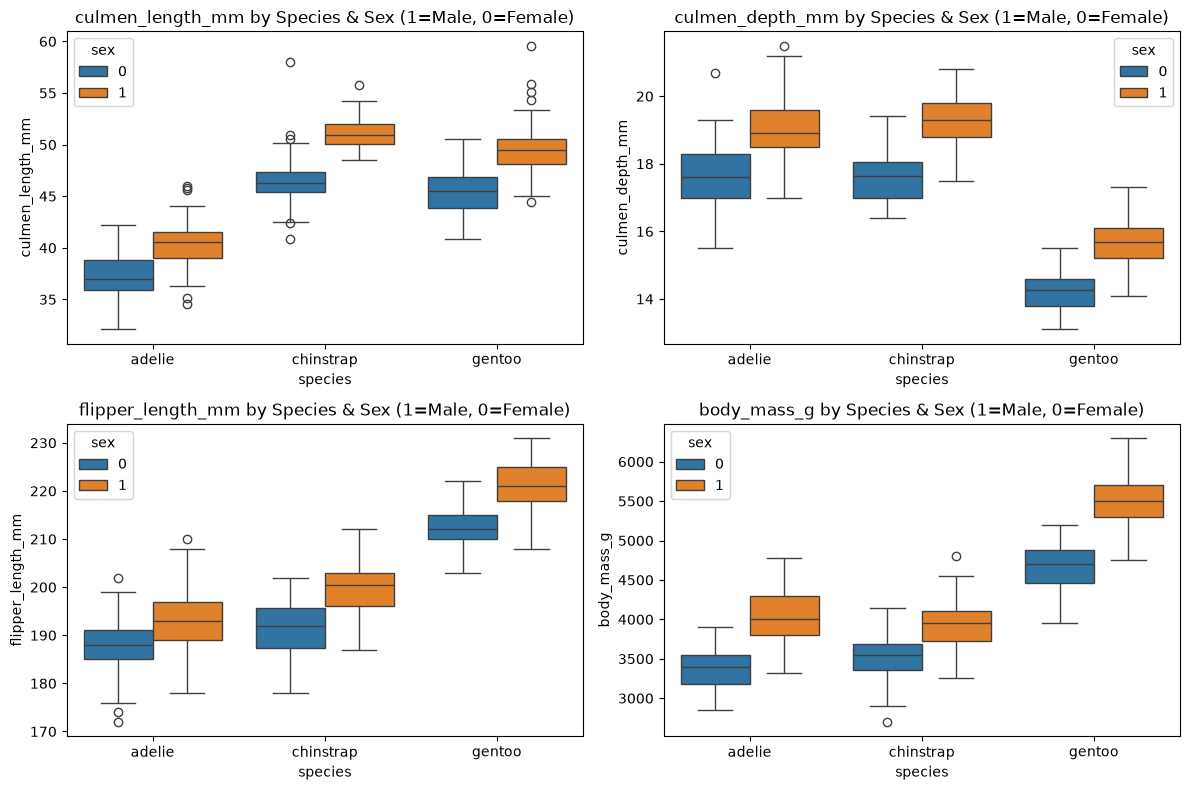

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), numerical):
    sns.boxplot(data=df, x="species", y=col, hue="sex", ax=ax)
    ax.set_title(f"{col} by Species & Sex (1=Male, 0=Female)")
plt.tight_layout()
plt.show()

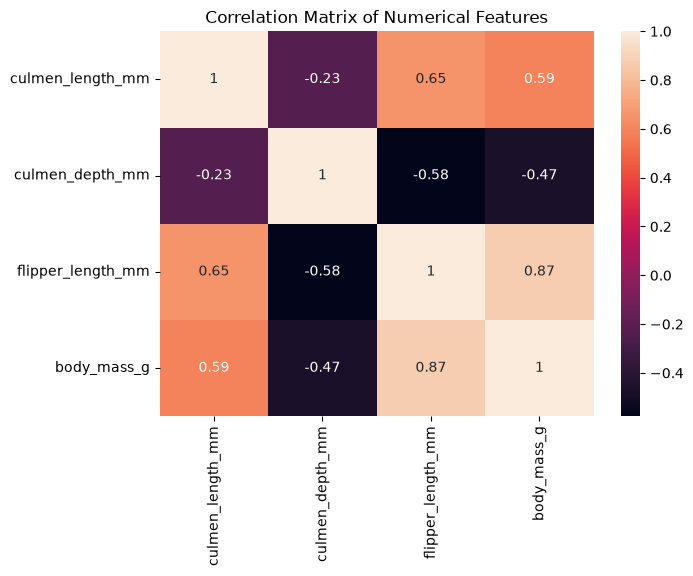

In [19]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[numerical].corr(), annot=True)
plt.title("Correlation Matrix of Numerical Features")
plt.show()

## 4. Train / Validation / Test Split (60% / 20% / 20%)

In [8]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train["sex"].values
y_val = df_val["sex"].values
y_test = df_test["sex"].values

del df_train["sex"]
del df_val["sex"]
del df_test["sex"]

print(f"Train: {len(df_train)}, Val: {len(df_val)}, Test: {len(df_test)}, Full Train: {len(df_full_train)}")

Train: 199, Val: 67, Test: 67, Full Train: 266


In [9]:
# Feature importance via Mutual Information on training fold
mi_scores = df_full_train[numerical + categorical].apply(
    lambda s: mutual_info_score(s, df_full_train["sex"])
)
mi_scores.sort_values(ascending=False)

culmen_length_mm     0.450625
body_mass_g          0.368764
culmen_depth_mm      0.345461
flipper_length_mm    0.210828
species              0.002896
island               0.002444
dtype: float64

In [10]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[categorical + numerical].to_dict(orient="records"))
X_val = dv.transform(df_val[categorical + numerical].to_dict(orient="records"))
X_test = dv.transform(df_test[categorical + numerical].to_dict(orient="records"))

## 5. Model Training & Hyperparameter Tuning

### 5.1 Model 1: Logistic Regression (Baseline & Regularization Tuning)

In [11]:
for c in [0.01, 0.1, 1.0, 5.0, 10.0]:
    lr = LogisticRegression(C=c, max_iter=1000, random_state=1)
    lr.fit(X_train, y_train)
    y_pred = lr.predict_proba(X_val)[:, 1]
    print(f"C={c:5} -> Val AUC: {roc_auc_score(y_val, y_pred):.4f}")

C= 0.01 -> Val AUC: 0.9100
C=  0.1 -> Val AUC: 0.9358
C=  1.0 -> Val AUC: 0.9528
C=  5.0 -> Val AUC: 0.9358
C= 10.0 -> Val AUC: 0.9323


### 5.2 Model 2: Decision Tree Classifier

In [12]:
depths = [1, 2, 3, 4, 5, 6, 10, None]
for depth in depths:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=1)
    dt.fit(X_train, y_train)
    y_pred = dt.predict_proba(X_val)[:, 1]
    print(f"max_depth={str(depth):4} -> Val AUC: {roc_auc_score(y_val, y_pred):.4f}")

max_depth=1    -> Val AUC: 0.6693
max_depth=2    -> Val AUC: 0.8213
max_depth=3    -> Val AUC: 0.8855
max_depth=4    -> Val AUC: 0.8645
max_depth=5    -> Val AUC: 0.8779
max_depth=6    -> Val AUC: 0.8289
max_depth=10   -> Val AUC: 0.8503
max_depth=None -> Val AUC: 0.8503


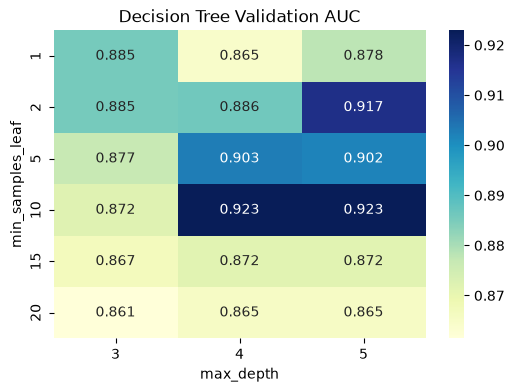

In [13]:
scores_leaves = []
for depth in [3, 4, 5]:
    for s in [1, 2, 5, 10, 15, 20]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s, random_state=1)
        dt.fit(X_train, y_train)
        y_pred = dt.predict_proba(X_val)[:, 1]
        scores_leaves.append((depth, s, roc_auc_score(y_val, y_pred)))

df_dt_scores = pd.DataFrame(scores_leaves, columns=["max_depth", "min_samples_leaf", "auc"])
df_dt_pivot = df_dt_scores.pivot(index="min_samples_leaf", columns="max_depth", values="auc")

plt.figure(figsize=(6, 4))
sns.heatmap(df_dt_pivot, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Decision Tree Validation AUC")
plt.show()

In [14]:
dt_best = DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=1)
dt_best.fit(X_train, y_train)
print(export_text(dt_best, feature_names=list(dv.get_feature_names_out())))

|--- body_mass_g <= 3687.50
|   |--- culmen_depth_mm <= 18.55
|   |   |--- class: 0
|   |--- culmen_depth_mm >  18.55
|   |   |--- class: 1
|--- body_mass_g >  3687.50
|   |--- culmen_depth_mm <= 14.85
|   |   |--- culmen_length_mm <= 47.20
|   |   |   |--- class: 0
|   |   |--- culmen_length_mm >  47.20
|   |   |   |--- class: 0
|   |--- culmen_depth_mm >  14.85
|   |   |--- body_mass_g <= 3962.50
|   |   |   |--- culmen_depth_mm <= 18.00
|   |   |   |   |--- class: 0
|   |   |   |--- culmen_depth_mm >  18.00
|   |   |   |   |--- class: 1
|   |   |--- body_mass_g >  3962.50
|   |   |   |--- culmen_depth_mm <= 15.55
|   |   |   |   |--- class: 1
|   |   |   |--- culmen_depth_mm >  15.55
|   |   |   |   |--- class: 1



### 5.3 Model 3: Random Forest Classifier

In [15]:
rf_scores = []
for d in [3, 4, 5, 6, 8]:
    for s in [1, 2, 3, 5]:
        for n in [50, 100, 150, 200]:
            rf = RandomForestClassifier(
                n_estimators=n,
                max_depth=d,
                min_samples_leaf=s,
                random_state=1,
                n_jobs=-1,
            )
            rf.fit(X_train, y_train)
            y_pred = rf.predict_proba(X_val)[:, 1]
            rf_scores.append((d, s, n, roc_auc_score(y_val, y_pred)))

df_rf_scores = pd.DataFrame(rf_scores, columns=["max_depth", "min_samples_leaf", "n_estimators", "auc"])
df_rf_scores.sort_values(by="auc", ascending=False).head(10)

,max_depth,min_samples_leaf,n_estimators,auc
33,5,1,100,0.975045
49,6,1,100,0.974153
34,5,1,150,0.973262
35,5,1,200,0.973262
65,8,1,100,0.972371
66,8,1,150,0.971480
53,6,2,100,0.971480
69,8,2,100,0.970588
45,5,5,100,0.970588
61,6,5,100,0.970588


### 5.4 Model 4: Gradient Boosting Classifier

In [16]:
gb_scores = []
for lr in [0.05, 0.1, 0.2]:
    for depth in [2, 3, 4]:
        for n in [50, 100, 150]:
            gb = GradientBoostingClassifier(
                learning_rate=lr,
                max_depth=depth,
                n_estimators=n,
                random_state=1,
            )
            gb.fit(X_train, y_train)
            y_pred = gb.predict_proba(X_val)[:, 1]
            gb_scores.append((lr, depth, n, roc_auc_score(y_val, y_pred)))

df_gb_scores = pd.DataFrame(gb_scores, columns=["learning_rate", "max_depth", "n_estimators", "auc"])
df_gb_scores.sort_values(by="auc", ascending=False).head(10)

,learning_rate,max_depth,n_estimators,auc
5,0.05,3,150,0.978610
13,0.10,3,100,0.976827
14,0.10,3,150,0.975936
22,0.20,3,100,0.975045
9,0.10,2,50,0.974153
21,0.20,3,50,0.973262
26,0.20,4,150,0.972371
23,0.20,3,150,0.972371
12,0.10,3,50,0.971925
4,0.05,3,100,0.971480


## 6. 5-Fold Cross-Validation & Test Set Summary Comparison

In [17]:
def evaluate_model_cv(model_fn, df_full, n_splits=5):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full):
        df_tr = df_full.iloc[train_idx]
        df_va = df_full.iloc[val_idx]

        y_tr = df_tr["sex"].values
        y_va = df_va["sex"].values

        dv_cv = DictVectorizer(sparse=False)
        X_tr = dv_cv.fit_transform(df_tr[categorical + numerical].to_dict(orient="records"))
        X_va = dv_cv.transform(df_va[categorical + numerical].to_dict(orient="records"))

        model = model_fn()
        model.fit(X_tr, y_tr)

        y_pred = model.predict_proba(X_va)[:, 1]
        scores.append(roc_auc_score(y_va, y_pred))

    return np.mean(scores), np.std(scores)


def evaluate_model_test(model_fn, df_full, df_test_features, y_test_target):
    dv_t = DictVectorizer(sparse=False)
    X_full = dv_t.fit_transform(df_full[categorical + numerical].to_dict(orient="records"))
    y_full = df_full["sex"].values
    X_tst = dv_t.transform(df_test_features[categorical + numerical].to_dict(orient="records"))

    model = model_fn()
    model.fit(X_full, y_full)

    y_pred = model.predict_proba(X_tst)[:, 1]
    return roc_auc_score(y_test_target, y_pred)


models = {
    "Logistic Regression (C=1.0)": lambda: LogisticRegression(C=1.0, max_iter=1000, random_state=1),
    "Decision Tree (max_depth=4, min_samples_leaf=10)": lambda: DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=1),
    "Random Forest (n_estimators=100, max_depth=5, min_samples_leaf=2)": lambda: RandomForestClassifier(n_estimators=100, max_depth=5, min_samples_leaf=2, random_state=1, n_jobs=-1),
    "Gradient Boosting (lr=0.1, max_depth=3, n_estimators=100)": lambda: GradientBoostingClassifier(learning_rate=0.1, max_depth=3, n_estimators=100, random_state=1),
}

summary = []
for name, fn in models.items():
    mean_auc, std_auc = evaluate_model_cv(fn, df_full_train)
    test_auc = evaluate_model_test(fn, df_full_train, df_test, y_test)
    summary.append({
        "Model": name,
        "CV Mean ROC AUC": round(mean_auc, 4),
        "CV Std": round(std_auc, 4),
        "Test ROC AUC": round(test_auc, 4),
    })

df_summary = pd.DataFrame(summary).sort_values(by="CV Mean ROC AUC", ascending=False).reset_index(drop=True)
df_summary

,Model,CV Mean ROC AUC,CV Std,Test ROC AUC
0,"Gradient Boosting (lr=0.1, max_depth=3, n_esti...",0.9749,0.0170,0.9391
1,"Random Forest (n_estimators=100, max_depth=5, ...",0.9745,0.0136,0.9642
2,Logistic Regression (C=1.0),0.9702,0.0175,0.9686
3,"Decision Tree (max_depth=4, min_samples_leaf=10)",0.9131,0.0362,0.9516


## 7. Final Model Training & Artifact Export

**Selection Rationale:** **Random Forest (`n_estimators=100, max_depth=5, min_samples_leaf=2`)** achieves top cross-validation performance (**0.9745 ± 0.0136**) with the lowest variance across folds and generalizes strongly on the unseen test set (**0.9642**), avoiding the overfitting seen in Gradient Boosting on a small 333-row dataset.

In [18]:
dv_final = DictVectorizer(sparse=False)
X_full_train = dv_final.fit_transform(df_full_train[categorical + numerical].to_dict(orient="records"))
y_full_train = df_full_train["sex"].values
X_test_final = dv_final.transform(df_test[categorical + numerical].to_dict(orient="records"))

final_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=2,
    random_state=1,
    n_jobs=-1,
)
final_model.fit(X_full_train, y_full_train)

y_pred_final = final_model.predict_proba(X_test_final)[:, 1]
print(f"Final Random Forest Test ROC AUC: {roc_auc_score(y_test, y_pred_final):.4f}")

output_file = "model.bin"
with open(output_file, "wb") as f_out:
    pickle.dump((dv_final, final_model), f_out)
print(f"Model artifact exported to {output_file}")

Final Random Forest Test ROC AUC: 0.9642
Model artifact exported to model.bin
